# 第1节部分
## 1.1 构成图的基本要素
构成图的基本要素部分,State（状态）真的存储了节点运行的所有数据吗?我记得在langchain实际运行时，还存在`runtime: Runtime`这种数据结构。

回答: State 承载工作流需要维护和传递的数据；节点还可以通过 Runtime 获取运行上下文、存储等依赖，通过 config 获取运行配置。State 无需包含节点执行所需的一切。 当前先理解这个边界即可。

## 1.2 图运行过程
LangGraph 的图运行过程基于 Superstep（超步） 来组织和推进。简单来说,包括以下3个步骤:
1. 在当前节点根据当前 State 和 Edge 的逻辑，确定本轮超步中应该被执行的节点。
2. 因为存在多个节点，并行运行本轮被选中的节点，并输出各自对状态的**局部更新**。
3. 根据节点的输出，合并更新 State。


## 1.3 Graph API vs Functional API
居然存在两种API

显然第二种适合简单一点的实现

# 2. 图的基础构建与运行

## 2.1 定义状态图

状态图的定义可以分为以下几个步骤：

**1. 定义全局状态**  定义整个运行图共享的全局状态（实际上，除了全局状态，LangGraph还支持其它类型的状态，下文详述）

**2. 创建状态图**     创建 StateGraph实例，将状态和状态图绑定

**3. 定义图结构**     定义节点和边并添加到状态图中

### 2.1.1 定义全局状态

全局状态是 LangGraph 运行图每个节点都可以访问的公共对象。

In [4]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph,START,END
from langgraph.graph import StateGraph



class OverAllstate(TypedDict):
    """
    全局状态，用于存储全局变量
    基础状态类

    """
    # 注解是为了规定字段,这里表明 logs更新的方式是 add而不是替代
    # 第一个参数 list[str]: 告诉静态类型检查器（如 mypy、IDE）以及开发者：这个变量是一个字符串列表（list of strings）
    # 第二个参数 add: 定义追加的方式。langgraph内部会读取第二个参数,然后以这种方式更新 logs
    logs: Annotated[list[str], add]
    cur_id: str

# 节点实际就是一个函数
def node_1(state: OverAllstate) -> OverAllstate:
    """
    节点 1
    """
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": state["cur_id"] + ",node_1"
    }

# 节点实际就是一个函数
def node_2(state: OverAllstate) -> OverAllstate:
    """
    节点 2
    """
    return {
        # 以追加的方式更新
        "logs": ["node_2 运行完毕"],
        "cur_id": state["cur_id"] + ",node_2"
    }
# 节点实际就是一个函数
# def node_3(state: OverAllstate) -> OverAllstate:
#     """
#     节点 3
#     """
#     return {
#         # 以追加的方式更新
#         "logs": ["node_3 运行完毕"],
#         "cur_id": state["cur_id"] + ",node_3"
#     }

# 3 定义边 与 图
# 3.1 创建图 获取建造者
builder = StateGraph(state_schema=OverAllstate)
# 3.2 添加节点
# 这里传入的是函数对象。LangGraph 保存它，并默认使用函数名 "node_1" 作为节点名，因此后面可以用这个字符串连接边。节点执行时，框架传入当前状态，接收它返回的字段更新；节点可以只返回需要更新的字段。
builder.add_node(node_1)
builder.add_node(node_2)
#builder.add_node(node_3)
# 3.2 添加边
# 3.2.1
# 3.3 添加边
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
#builder.add_edge("node_1","node_3")
# 陷入循环会 报错 超过调用次数: GraphRecursionError: Recursion limit of 10007 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
# builder.add_edge("node_2","node_1")
builder.add_edge("node_2", END)
#builder.add_edge("node_3",END)

# 4 获取图
# 校验图结构，构造可执行图，此时还没有运行你们的两个业务节点。
graph = builder.compile()

# 5 运行图
# invoke: 初始状态
result = graph.invoke({"cur_id":"start"})
print(result)

{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start,node_1,node_2'}


TypedDict 描述字典有哪些字段及其类型；它本身不会在运行时自动检查每个值，也不会自动给所有字段填默认值。Annotated 则允许在类型旁附带额外信息

这里真正让 add 生效的是 LangGraph：它读取注解，把 add 注册为 logs 的合并函数。因此：
```python
新的 logs = add(旧的 logs, 节点返回的 logs)
新的 cur_id = 节点返回的 cur_id
```

In [6]:
for state in graph.stream(
    {"cur_id": "start"},
    stream_mode="values",
):
    print(f"state={state}")

state={'logs': [], 'cur_id': 'start'}
state={'logs': ['node_1 运行完毕'], 'cur_id': 'start,node_1'}
state={'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start,node_1,node_2'}


## 2.2. 图结构可视化

### 2.2.1. 绘制mermaid并获取源码

mermaid是一种生成图表和流程图的文本标记语言，它可以把简单的文本描述直接渲染成可视化图形。

通过以下代码可以用mermaid语法表达图结构，并打印mermaid源码

In [3]:
raw_mermaid = graph.get_graph().draw_mermaid()
print(raw_mermaid)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	node_1(node_1)
	node_2(node_2)
	__end__([<p>__end__</p>]):::last
	__start__ --> node_1;
	node_1 --> node_2;
	node_2 --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 2.2.2 Jupyter 直接绘图

Graph(
    nodes={
        '__start__': Node(
            id='__start__',
            name='__start__',
            data=RunnableCallable(tags=None, recurse=True, explode_args=False, func_accepts={}),
            metadata=None
        ),
        'node_1': Node(
            id='node_1',
            name='node_1',
            data=node_1(tags=None, recurse=True, explode_args=False, func_accepts={}),
            metadata=None
        ),
        'node_2': Node(
            id='node_2',
            name='node_2',
            data=node_2(tags=None, recurse=True, explode_args=False, func_accepts={}),
            metadata=None
        ),
        '__end__': Node(id='__end__', name='__end__', data=None, metadata=None)
    },
    edges=[
        Edge(source='__start__', target='node_1', data=None, conditional=False),
        Edge(source='node_1', target='node_2', data=None, conditional=False),
        Edge(source='node_2', target='__end__', data=None, conditional=False)
    ]
)

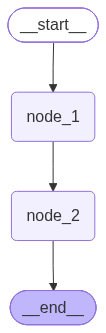

In [7]:
from IPython.display import Image, display
from rich import print as rprint
rprint(graph.get_graph())
display(Image(graph.get_graph().draw_mermaid_png()))

### 2.2.3  快捷展示

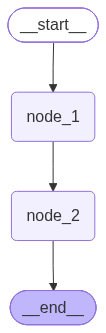

In [ ]:
from IPython.display import display

display(graph)
#display() 函数是 Jupyter Notebook 和 IPython 交互式环境中的核心渲染工具，用于以富文本、图形或表格等最优格式显示各种 Python 对

# 现象记录

1. 当构建的图出现循环时，会出现: 报错 超过调用次数: GraphRecursionError: Recursion limit of 10007 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.

2. 当存在并行路线时，会出现 `InvalidUpdateError: At key 'cur_id': Can receive only one value per step.
Use an Annotated key to handle multiple values.` 错误。这是因为虽然我们给 logs 定义了 reducer add，但是 cur_id 没有定义。默认只接受每步恰好一个值。

虽然 reducer 默认采取覆盖方式，但在并行线路上，模型可能因为响应速度出现节点执行顺序不一的情况，如果不规定 reducer ，会出现 多次运行不同结果的情况。